# Statistical Analysis: Is the Price Gap Larger than Chance?
This notebook compares price per pack for Mainstream Young Singles/Couples
with all other customers, using a permutation test and a bootstrap interval.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sys
from pathlib import Path
sys.path.append(str(Path("../src").resolve()))

from stats import (
    difference_in_means,
    permutation_test,
    bootstrap_two_sample,
    percentile_interval,
)

SEED = 556
N_PERM = 10_000
N_BOOT = 10_000

from features import card_level_summary

In [3]:
df_cust = pd.read_csv("../data/processed/processed_data.csv", parse_dates=["DATE"])

assert len(df_cust) == 246739
assert df_cust["price_per_pack"].notna().all()
print(df_cust.shape)

(246739, 13)


In [4]:
rng = np.random.default_rng(SEED)
fake_a = rng.normal(0, 1, 1000)
fake_b = rng.normal(0.5, 1, 1000)   # true gap is -0.5

observed, p_value, null = permutation_test(
    fake_a, fake_b, n_perm=2000, rng=np.random.default_rng(SEED)
)
boot = bootstrap_two_sample(
    fake_a, fake_b, n_boot=2000, rng=np.random.default_rng(SEED)
)

print(f"observed difference: {observed:.3f}")
print(f"permutation p-value: {p_value:.5f}")
print("95% bootstrap interval:", percentile_interval(boot))

observed difference: -0.500
permutation p-value: 0.00050
95% bootstrap interval: (-0.5857326103436393, -0.40942637994452075)


## Method check on simulated data
Before using the functions on the real data, I tested them on two simulated
groups with a known gap of -0.5. They recovered it, with a very small p-value
and an interval around -0.5, so the code behaves as expected.

In [5]:
cards = card_level_summary(df_cust)
assert cards["LYLTY_CARD_NBR"].is_unique      # one row per card

in_focus = (
    (cards["LIFESTAGE"] == "YOUNG SINGLES/COUPLES")
    & (cards["PREMIUM_CUSTOMER"] == "Mainstream")
)
group_a = cards.loc[in_focus, "price_per_pack"].to_numpy()
group_b = cards.loc[~in_focus, "price_per_pack"].to_numpy()

print("cards in total:", len(cards))
print(f"focus segment: {len(group_a):,} cards, mean ${group_a.mean():.3f}")
print(f"all others:    {len(group_b):,} cards, mean ${group_b.mean():.3f}")
print(f"observed gap:  ${difference_in_means(group_a, group_b):.3f}")

cards in total: 71287
focus segment: 7,917 cards, mean $4.129
all others:    63,370 cards, mean $3.845
observed gap:  $0.284


In [6]:
## Permutation Test and Bootstrap Confidence Interval

observed, p_value, null = permutation_test(
    group_a, group_b, n_perm=N_PERM, rng=np.random.default_rng(SEED)
)
boot = bootstrap_two_sample(
    group_a, group_b, n_boot=N_BOOT, rng=np.random.default_rng(SEED)
)
lower, upper = percentile_interval(boot)

print(f"observed gap: ${observed:.3f}")
print(f"permutation p-value: {p_value:.5f}")
print(f"shuffled gaps: SD = ${null.std():.4f}, largest |gap| = ${np.abs(null).max():.4f}")
print(f"95% bootstrap interval: (${lower:.3f}, ${upper:.3f})")

observed gap: $0.284
permutation p-value: 0.00010
shuffled gaps: SD = $0.0096, largest |gap| = $0.0355
95% bootstrap interval: ($0.266, $0.301)


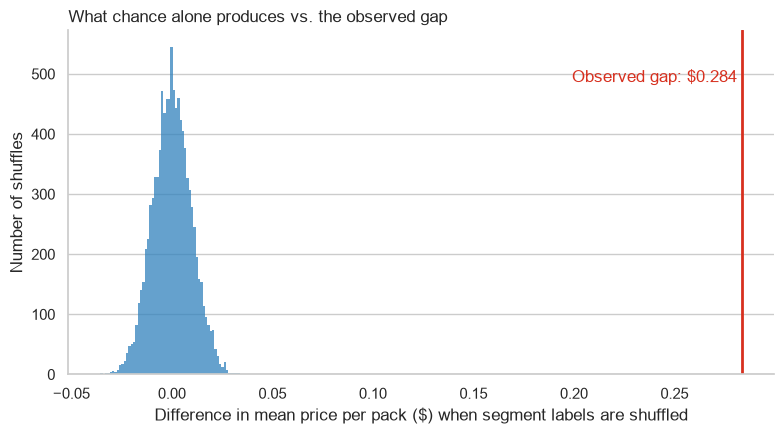

In [8]:
## Permutation Test Results

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(null, bins=60, color="#3182bd", linewidth=0, ax=ax)
ax.grid(axis="x", visible=False)
ax.axvline(observed, color="#d7301f", linewidth=2)
ax.text(observed, ax.get_ylim()[1] * 0.85, f"Observed gap: ${observed:.3f} ",
        color="#d7301f", ha="right")
ax.set_xlabel("Difference in mean price per pack ($) when segment labels are shuffled")
ax.set_ylabel("Number of shuffles")
ax.set_title("What chance alone produces vs. the observed gap", loc="left")
sns.despine(ax=ax)
fig.tight_layout()

fig.savefig("../figures/04_permutation.png", dpi=200, bbox_inches="tight")
plt.show()

SEED CHECK

In [9]:
rows = []
for seed in [1, 2, 3, 4, 5]:
    _, p, null_s = permutation_test(
        group_a, group_b, n_perm=2000, rng=np.random.default_rng(seed)
    )
    boot_s = bootstrap_two_sample(
        group_a, group_b, n_boot=2000, rng=np.random.default_rng(seed)
    )
    lo, hi = percentile_interval(boot_s)
    rows.append({
        "seed": seed,
        "p_value": round(p, 5),
        "null_sd": round(null_s.std(), 4),
        "ci_lower": round(lo, 3),
        "ci_upper": round(hi, 3),
    })

pd.DataFrame(rows)

,seed,p_value,null_sd,ci_lower,ci_upper
0,1,0.0005,0.0096,0.266,0.302
1,2,0.0005,0.0094,0.266,0.301
2,3,0.0005,0.0095,0.266,0.301
3,4,0.0005,0.0096,0.267,0.301
4,5,0.0005,0.0095,0.266,0.302


## How the methods work

**Permutation test.** The question is whether the gap in average price per
pack between the focus segment and everyone else could be due to chance. If
segment had no relationship to price, the segment labels would be arbitrary.
So I pooled the 71,287 card prices, randomly reassigned them into a group of
7,917 and a group of 63,370, and recorded the difference in means. I repeated
this 10,000 times. The result is the set of gaps that chance alone produces.
The p-value is the share of those shuffled gaps that were at least as extreme
as the observed gap.

**Bootstrap.** To measure how precisely the gap is estimated, I resampled the
cards in each group with replacement, keeping each group's size, and
recomputed the gap. I repeated this 10,000 times. The middle 95% of those gaps
is a 95% percentile interval for the true gap.

Both methods use one value per loyalty card, so a customer with many purchases
is not counted many times.

## Results and interpretation

Mainstream Young Singles/Couples pay on average about $0.28 more per pack
($4.13 vs $3.85) than all other customers. In 10,000 shuffles, none produced a
gap as large as the observed one (p < 0.0001). The shuffled gaps had a standard
deviation of about one cent, and the largest was 3.6 cents, so the observed gap
is far outside what chance produces. The 95% bootstrap interval for the gap is
about $0.27 to $0.30, so the gap is clearly different from zero and estimated
precisely.

Repeating the analysis with five different random seeds gave the same
conclusion, so the result does not depend on the random numbers used.

This shows that the segment's higher price per pack is not due to chance. It
does not show why. The segment may buy larger packs or more expensive brands,
rather than paying more for the same product.